# Tecnología, cultura y vida universitaria en las noticias de la Unison (2015–2026)

**La pregunta de la historia:** ¿las noticias de la Universidad de Sonora reflejan el progreso tecnológico y cultural de Sonora?
Si un tema se vuelve importante en el estado (por ejemplo, los semiconductores), ¿la universidad habla de él, y cuándo?

Lo vamos a responder en tres pasos:

1. **Este notebook:** encontrar los temas importantes de cada año en las noticias de la Unison, en tres grupos:
   - **Tecnología.**
   - **Cultura:** festivales, artes, eventos, cine independiente y obra personal (libros, exposiciones).
   - **Vida universitaria:** gobierno de la universidad, presupuesto, sindicatos, elección de rector(a).
2. **Después:** comparar esos temas con el interés del público (Google Trends).
3. **Después:** comparar con lo que publican otros medios de Sonora y de México.

Para encontrar los temas usamos **modelado de temas** (*topic modeling*), que agrupa las noticias según las palabras que comparten.

## 1. Librerías

In [1]:
import json
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import NMF

## 2. Carga de datos

Usamos las noticias y los **lemas** que calculamos en `02_temas_por_anio.ipynb` (ya limpios y separados en *temas*,
es decir sustantivos y adjetivos, y *nombres* propios).

In [2]:
RUTA_LEMAS = "data/processed/noticias_lemas.jsonl"
if not os.path.exists(RUTA_LEMAS):
    raise FileNotFoundError("Primero hay que correr 02_temas_por_anio.ipynb: ahí se generan los lemas.")

registros = []
with open("data/raw/noticias_unison.jsonl", encoding="utf-8") as archivo:
    for linea in archivo:
        try:
            registros.append(json.loads(linea))
        except json.JSONDecodeError:
            pass  # línea incompleta mientras el scraper escribe

noticias = pd.DataFrame(registros)
noticias = noticias[noticias["estado"] == "ok"].drop_duplicates(subset="id", keep="last")
noticias = noticias.sort_values("id").reset_index(drop=True)
noticias["fecha"] = pd.to_datetime(noticias["fecha"])
noticias["anio"] = noticias["fecha"].dt.year
noticias["n_palabras"] = noticias["n_palabras"].astype(int)
noticias = noticias[noticias["n_palabras"] >= 30].reset_index(drop=True)
noticias = noticias[["id", "fecha", "anio", "titulo", "texto"]]

lemas = pd.read_json(RUTA_LEMAS, lines=True)
noticias = noticias.merge(lemas, on="id")
noticias["terminos"] = noticias["temas"] + noticias["nombres"]

noticias_por_anio = noticias["anio"].value_counts().sort_index()
anios = list(noticias_por_anio.index)
print("Noticias:", len(noticias))

Noticias: 19813


## 3. Los temas generales

### 3.1 ¿Cómo funciona el modelado de temas?

1. Representamos cada noticia con **TF-IDF**: un número por palabra que dice qué tan importante es esa palabra en la noticia
   (frecuente en ella, rara en las demás). Queda una tabla enorme de noticias × palabras.
2. **NMF** (*factorización de matrices no negativas*) resume esa tabla en unos cuantos **temas**. Cada tema es una lista de palabras
   con pesos (*música, concierto, piano...*) y cada noticia es una mezcla de temas.
3. A cada noticia le asignamos su **tema dominante**: el de mayor peso.

El número de temas lo elegimos nosotros. Probamos 30, 45, 50 y 70: con 30 la tecnología queda en un solo tema muy general;
con 45 ya se separan, por ejemplo, la inteligencia artificial y la energía solar; con más de 50 aparecen temas de una sola persona.

Usamos solo los **temas** (sustantivos y adjetivos) y no los nombres propios, porque con nombres se forman temas de personas
(por ejemplo, uno de la rectora).

In [3]:
# Nuestras noticias ya vienen como listas de lemas, así que el vectorizador las usa tal cual (analyzer).
# min_df=10: la palabra debe aparecer en al menos 10 noticias; max_df=0.3: quitamos las que están en más del 30%.
vectorizador = TfidfVectorizer(analyzer=lambda terminos: terminos, min_df=10, max_df=0.3)
matriz = vectorizador.fit_transform(noticias["temas"])
palabras = vectorizador.get_feature_names_out()

print("Noticias x palabras:", matriz.shape)

Noticias x palabras: (19813, 20948)


In [4]:
N_TEMAS = 45

nmf = NMF(n_components=N_TEMAS, init="nndsvd", random_state=0, max_iter=400)
pesos = nmf.fit_transform(matriz)          # noticias x temas: cuánto pesa cada tema en cada noticia
noticias["tema"] = pesos.argmax(axis=1)    # tema dominante


def palabras_del_tema(modelo, palabras, numero, n=10):
    """Las n palabras con más peso en un tema."""
    mas_pesadas = modelo.components_[numero].argsort()[::-1][:n]
    return ", ".join(palabras[mas_pesadas])


temas_generales = pd.DataFrame({
    "palabras": [palabras_del_tema(nmf, palabras, numero) for numero in range(N_TEMAS)],
    "noticias": noticias["tema"].value_counts().sort_index(),
})
pd.set_option("display.max_colwidth", 120)
temas_generales

,palabras,noticias
tema,,
0,"investigación, posgrado, investigador, científico, estancia, maestría, doctorado, internacional, tesis, nivel",64
1,"mujer, hombre, femenino, derecho, lucha, igualdad, madre, marzo, laboral, feminista",259
2,"música, concierto, musical, piano, pieza, escenario, compositor, recital, ópera, presentación",662
3,"reconocimiento, ceremonia, maestro, generación, mejor, vida, esfuerzo, entrega, egresado, familia",580
4,"salud, enfermedad, médico, mental, salud mental, prevención, atención, paciente, enfermería, cuidado",831
5,"aspirante, examen, inscripción, convocatoria, junio, ingreso, registro, proceso, agosto, mayo",364
6,"ciencia, científico, física, matemática, divulgación, conocimiento, tecnología, matemático, ingeniería, investigador",198
7,"economía, económico, país, mexicano, crecimiento, política, gobierno, inversión, mercado, situación",412
8,"lugar, concurso, categoría, ganador, primer lugar, segundo, segundo lugar, tercer, tercer lugar, equipo",219


### 3.2 Ponerles nombre

El modelo no sabe cómo se llaman los temas: les ponemos nombre leyendo sus palabras.
*Si cambian los datos o el número de temas, la numeración cambia y hay que revisar estas etiquetas.*

In [5]:
ETIQUETAS = {
    0: "Investigación y posgrado", 1: "Mujeres e igualdad", 2: "Música", 3: "Ceremonias y reconocimientos",
    4: "Salud", 5: "Admisión e inscripciones", 6: "Ciencia y divulgación", 7: "Economía",
    8: "Concursos", 9: "Formación profesional", 10: "Libros y literatura", 11: "Congresos y conferencias",
    12: "Sorteos", 13: "Medio ambiente y agua", 14: "Justicia y derecho", 15: "Empresas e innovación",
    16: "Acreditación y calidad", 17: "Cursos y talleres", 18: "Mediación y cultura de paz", 19: "Cáncer de mama",
    20: "Diplomados y titulación", 21: "Niñez y familia", 22: "Servicio social", 23: "Alimentación y nutrición",
    24: "Proyectos y convocatorias", 25: "Educación superior", 26: "Deporte", 27: "Avisos y horarios",
    28: "Campus y comunidad universitaria", 29: "Violencia de género", 30: "Convenios", 31: "Lenguas indígenas",
    32: "Vida estudiantil y movilidad", 33: "Investigación de laboratorio", 34: "Medallas deportivas",
    35: "Protección civil", 36: "Artes escénicas y visuales", 37: "Gobierno y transparencia", 38: "Cambio climático",
    39: "Perspectiva de género", 40: "Tecnología digital e IA", 41: "Energía", 42: "Discapacidad e inclusión",
    43: "Nombramientos y órganos de gobierno", 44: "Historia y cine",
}

temas_generales.insert(0, "etiqueta", pd.Series(ETIQUETAS))
temas_generales[["etiqueta", "palabras", "noticias"]]

,etiqueta,palabras,noticias
tema,,,
0,Investigación y posgrado,"investigación, posgrado, investigador, científico, estancia, maestría, doctorado, internacional, tesis, nivel",64
1,Mujeres e igualdad,"mujer, hombre, femenino, derecho, lucha, igualdad, madre, marzo, laboral, feminista",259
2,Música,"música, concierto, musical, piano, pieza, escenario, compositor, recital, ópera, presentación",662
3,Ceremonias y reconocimientos,"reconocimiento, ceremonia, maestro, generación, mejor, vida, esfuerzo, entrega, egresado, familia",580
4,Salud,"salud, enfermedad, médico, mental, salud mental, prevención, atención, paciente, enfermería, cuidado",831
5,Admisión e inscripciones,"aspirante, examen, inscripción, convocatoria, junio, ingreso, registro, proceso, agosto, mayo",364
6,Ciencia y divulgación,"ciencia, científico, física, matemática, divulgación, conocimiento, tecnología, matemático, ingeniería, investigador",198
7,Economía,"economía, económico, país, mexicano, crecimiento, política, gobierno, inversión, mercado, situación",412
8,Concursos,"lugar, concurso, categoría, ganador, primer lugar, segundo, segundo lugar, tercer, tercer lugar, equipo",219


### 3.3 Tres grupos: tecnología, cultura y vida universitaria

Juntamos los temas que nos interesan en tres grupos. El resto (salud, deporte, trámites, etc.) queda como "Otros".

In [6]:
GRUPOS = {
    "Tecnología": [40, 41, 15, 6],      # tecnología digital e IA, energía, empresas e innovación, ciencia y divulgación
    "Cultura": [2, 10, 36, 44],         # música, libros, artes escénicas y visuales, historia y cine
    "Vida universitaria": [43, 25, 30, 37],  # nombramientos y órganos de gobierno, educación superior, convenios, gobierno
}

for grupo, numeros in GRUPOS.items():
    print(grupo + ":", ", ".join(ETIQUETAS[numero] for numero in numeros))

grupo_de_tema = {numero: grupo for grupo, numeros in GRUPOS.items() for numero in numeros}
noticias["grupo"] = noticias["tema"].map(grupo_de_tema).fillna("Otros")

por_grupo = pd.crosstab(noticias["anio"], noticias["grupo"], normalize="index") * 100
por_grupo.round(1)

Tecnología: Tecnología digital e IA, Energía, Empresas e innovación, Ciencia y divulgación
Cultura: Música, Libros y literatura, Artes escénicas y visuales, Historia y cine
Vida universitaria: Nombramientos y órganos de gobierno, Educación superior, Convenios, Gobierno y transparencia


grupo,Cultura,Otros,Tecnología,Vida universitaria
anio,,,,
2015,16.4,65.5,7.8,10.3
2016,16.5,63.4,7.9,12.2
2017,13.5,64.0,7.8,14.7
2018,11.5,68.3,7.1,13.0
2019,11.3,64.7,9.6,14.5
2020,9.2,64.4,12.5,14.0
2021,8.6,60.5,14.6,16.2
2022,10.9,69.6,10.5,8.9
2023,13.0,70.2,8.0,8.7


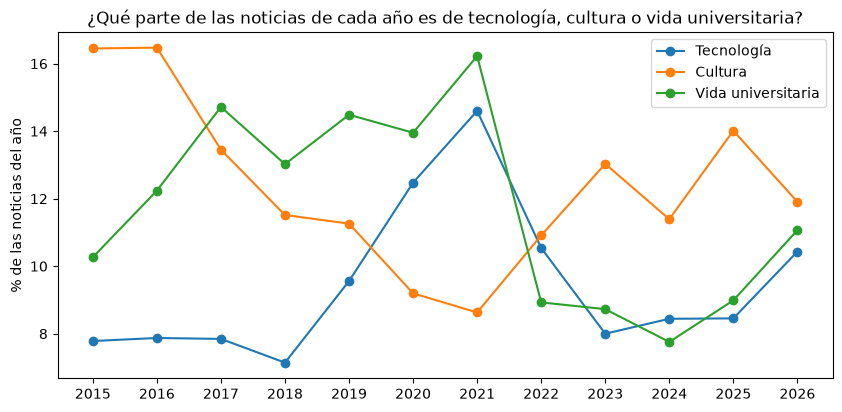

In [7]:
plt.figure(figsize=(10, 4.5))
for grupo in GRUPOS:
    plt.plot(por_grupo.index, por_grupo[grupo], marker="o", label=grupo)

plt.title("¿Qué parte de las noticias de cada año es de tecnología, cultura o vida universitaria?")
plt.ylabel("% de las noticias del año")
plt.xticks(anios)
plt.legend()
plt.show()

Y dentro de cada grupo, cada tema por separado:

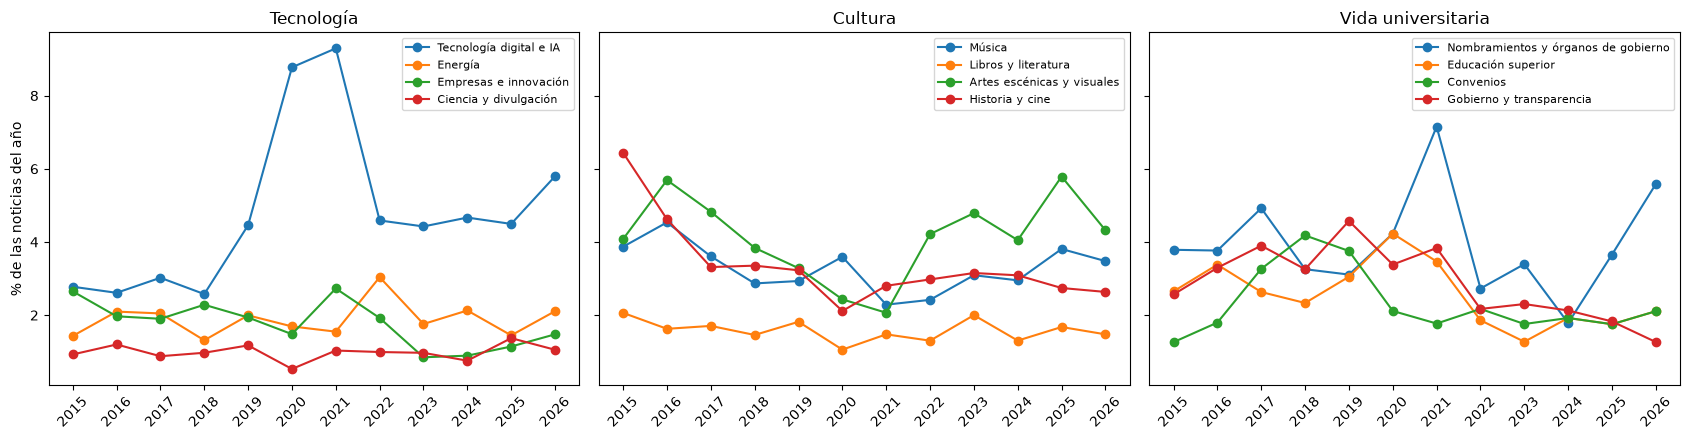

In [8]:
fig, ejes = plt.subplots(1, 3, figsize=(17, 4.5), sharey=True)

for (grupo, numeros), eje in zip(GRUPOS.items(), ejes):
    for numero in numeros:
        porcentaje = (noticias["tema"] == numero).groupby(noticias["anio"]).mean() * 100
        eje.plot(porcentaje.index, porcentaje.values, marker="o", label=ETIQUETAS[numero])
    eje.set_title(grupo)
    eje.set_xticks(anios)
    eje.tick_params(axis="x", rotation=45)
    eje.legend(fontsize=8)

ejes[0].set_ylabel("% de las noticias del año")
plt.tight_layout()
plt.show()

## 4. Temas específicos dentro de tecnología y cultura

Los temas generales todavía son amplios: "Tecnología digital e IA" mezcla la inteligencia artificial con las clases virtuales
de la pandemia. Repetimos el modelado **solo con las noticias de cada grupo** para encontrar temas más específicos.

En cultura usamos también los **nombres propios**, porque muchos eventos se reconocen por su nombre
(*FAOT*, *teatro Emiliana de Zubeldía*).

In [9]:
def subtemas(numeros, n_subtemas, columna):
    """Modelo de temas solo con las noticias cuyo tema dominante está en `numeros`."""
    grupo = noticias[noticias["tema"].isin(numeros)].copy()
    vectorizador_grupo = TfidfVectorizer(analyzer=lambda terminos: terminos, min_df=5, max_df=0.4)
    matriz_grupo = vectorizador_grupo.fit_transform(grupo[columna])

    modelo = NMF(n_components=n_subtemas, init="nndsvd", random_state=0, max_iter=500)
    grupo["subtema"] = modelo.fit_transform(matriz_grupo).argmax(axis=1)

    palabras_grupo = vectorizador_grupo.get_feature_names_out()
    resumen = pd.DataFrame({
        "palabras": [palabras_del_tema(modelo, palabras_grupo, numero) for numero in range(n_subtemas)],
        "noticias": grupo["subtema"].value_counts().sort_index(),
    })
    return grupo, resumen


def dibujar_mapa(tabla, titulo, formato="{:.1f}"):
    """Mapa de calor de una tabla (filas x años) con el valor escrito en cada celda.

    Cada fila se colorea con su propia escala (el año más alto de cada tema es el más oscuro),
    para ver cuándo destaca cada tema aunque unos sean mucho más grandes que otros.
    """
    colores = tabla.div(tabla.max(axis=1), axis=0)

    plt.figure(figsize=(13, 0.45 * len(tabla) + 1.5))
    plt.imshow(colores, cmap="Blues", aspect="auto")
    plt.yticks(range(len(tabla)), tabla.index)
    plt.xticks(range(len(tabla.columns)), tabla.columns)
    for i in range(len(tabla)):
        for j in range(len(tabla.columns)):
            plt.text(j, i, formato.format(tabla.iloc[i, j]), ha="center", va="center", fontsize=8,
                     color="white" if colores.iloc[i, j] > 0.6 else "black")   # celdas oscuras: texto en blanco
    plt.title(titulo + "\n(color: cada fila con su propia escala; el número es el % real)")
    plt.show()


def porcentaje_por_anio_de(grupo, etiquetas):
    """% de las noticias de cada año (de todas) cuyo subtema es cada uno de los subtemas del grupo."""
    conteo = pd.crosstab(grupo["subtema"], grupo["anio"]).reindex(columns=anios, fill_value=0)
    conteo.index = [etiquetas[numero] for numero in conteo.index]
    return conteo / noticias_por_anio * 100

### 4.1 Tecnología

In [10]:
tecnologia, resumen_tecnologia = subtemas(GRUPOS["Tecnología"], 12, columna="temas")
resumen_tecnologia

,palabras,noticias
subtema,,
0,"empresa, negocio, sector, emprendedor, empresarial, innovación, industria, mercado, emprendimiento, laboral",342
1,"energía, solar, renovable, energía solar, energético, energías renovables, proyecto, eléctrico, fotovoltaico, limpio",208
2,"ciencia, evento, científico, matemática, divulgación, conferencia, taller, organizador, comité, comité organizador",246
3,"docente, alumno, virtual, clase, aprendizaje, educativo, enseñanza, pandemia, educación, herramienta",185
4,"artificial, inteligencia, inteligencia artificial, dato, tecnología, sistema, humano, herramienta, modelo, aplicación",148
5,"revista, científico, publicación, editorial, artículo, abierto, revistas científicas, calidad, ciencia abierta, acce...",46
6,"edición, órgano, página, publicación, órgano difusión, portada, versión, apartado, versión línea, evento",41
7,"comunicación, social, medio, periodismo, red, redes sociales, periodista, radio, organizacional, organización",156
8,"solar, sol, eclipse, hora, noche, astronómico, cielo, día, fenómeno, hemisferio",73


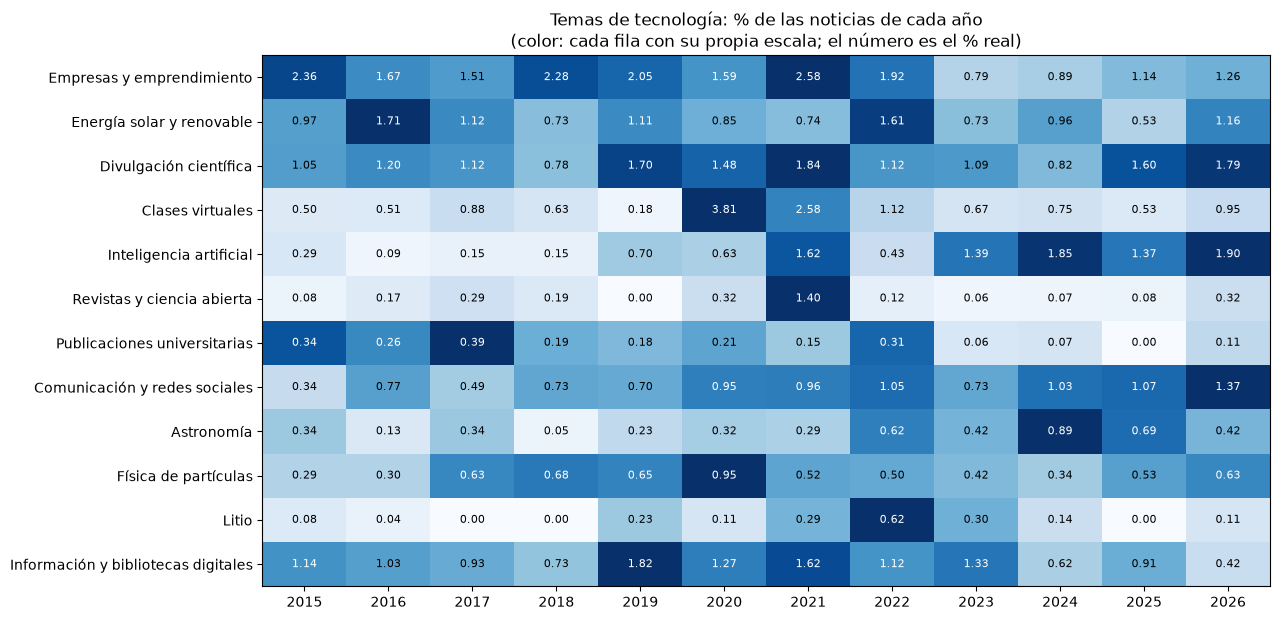

In [11]:
ETIQUETAS_TECNOLOGIA = {
    0: "Empresas y emprendimiento", 1: "Energía solar y renovable", 2: "Divulgación científica",
    3: "Clases virtuales", 4: "Inteligencia artificial", 5: "Revistas y ciencia abierta",
    6: "Publicaciones universitarias", 7: "Comunicación y redes sociales", 8: "Astronomía",
    9: "Física de partículas", 10: "Litio", 11: "Información y bibliotecas digitales",
}

tabla_tecnologia = porcentaje_por_anio_de(tecnologia, ETIQUETAS_TECNOLOGIA)
dibujar_mapa(tabla_tecnologia, "Temas de tecnología: % de las noticias de cada año", formato="{:.2f}")

### 4.2 Cultura

In [12]:
cultura, resumen_cultura = subtemas(GRUPOS["Cultura"], 12, columna="terminos")
resumen_cultura

,palabras,noticias
subtema,,
0,"danza, artes escénicas, escénicas, danza contemporánea, coreografía, coreográfico, licenciatura artes, contemporánea...",187
1,"libro, méxico, investigación, social, nacional, tema, investigador, movimiento, estudio, antropología",600
2,"música, concierto, guitarra, piano, musical, licenciatura música, recital, viernes, alumno, viernes concierto",304
3,"película, canal, hora, programación, señal, cine, cable, domingo, sistema cable, televisión",133
4,"lectura, libro, biblioteca, siembra, rayas, pesqueira, fernando pesqueira, rayas solís, cosecha, solís",128
5,"teatro, escena, emiliana, zubeldía, emiliana zubeldía, academia, dramático, teatral, arte dramático, puesta escena",325
6,"exposición, artes plásticas, plásticas, artista, pintura, arte, plástico, dibujo, técnica, art",246
7,"danza, mestiza, tradición mestiza, tradición, grupo, mexicano, amador, festival, folclórico, méxico",61
8,"archivo, histórico, archivo histórico, documento, fotografía, patrimonio, imagen, exposición, acervo, histórico univ...",93


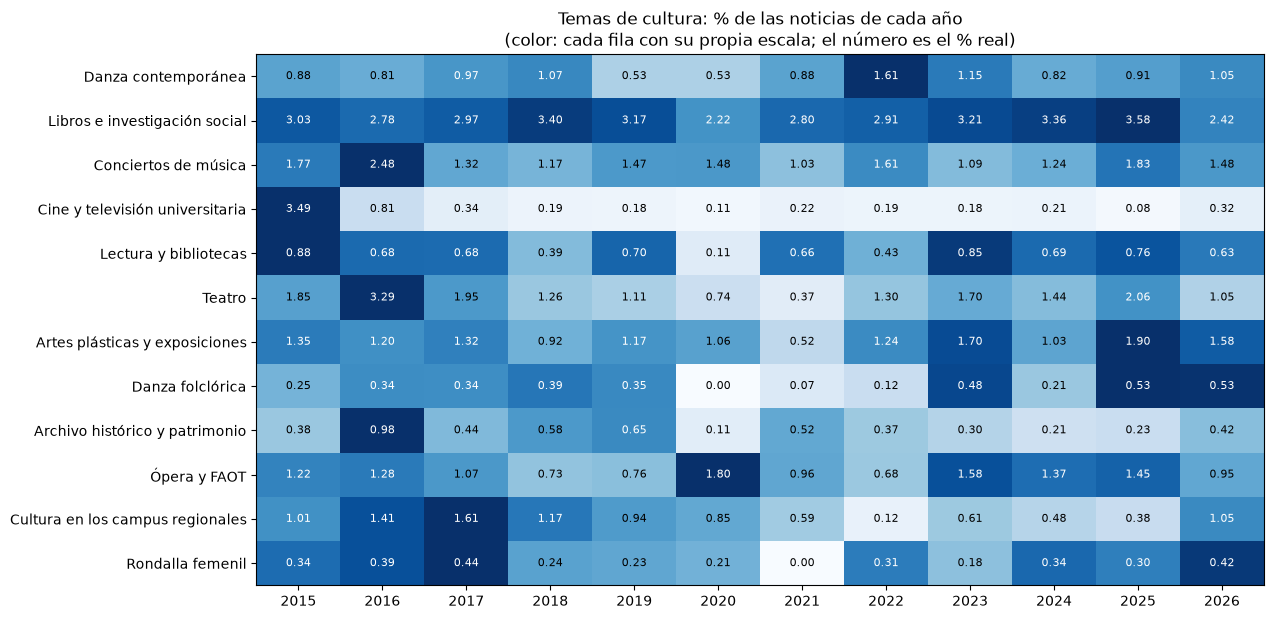

In [13]:
ETIQUETAS_CULTURA = {
    0: "Danza contemporánea", 1: "Libros e investigación social", 2: "Conciertos de música",
    3: "Cine y televisión universitaria", 4: "Lectura y bibliotecas", 5: "Teatro",
    6: "Artes plásticas y exposiciones", 7: "Danza folclórica", 8: "Archivo histórico y patrimonio",
    9: "Ópera y FAOT", 10: "Cultura en los campus regionales", 11: "Rondalla femenil",
}

tabla_cultura = porcentaje_por_anio_de(cultura, ETIQUETAS_CULTURA)
dibujar_mapa(tabla_cultura, "Temas de cultura: % de las noticias de cada año", formato="{:.2f}")

### 4.3 El tema destacado de cada año

En los mapas, los temas grandes ganan casi todos los años. Para encontrar lo que **distingue** a cada año comparamos
cada tema con su propio promedio: el tema destacado es el que ese año está **más por encima de su promedio**
(pidiendo al menos 5 noticias, para no premiar casualidades).

In [14]:
def destacado_por_anio(tabla, grupo, etiquetas):
    """Para cada año, el tema que más supera su propio promedio (con al menos 5 noticias ese año)."""
    conteo = pd.crosstab(grupo["subtema"], grupo["anio"]).reindex(columns=anios, fill_value=0)
    conteo.index = [etiquetas[numero] for numero in conteo.index]

    veces_su_promedio = tabla.div(tabla.mean(axis=1), axis=0)
    veces_su_promedio = veces_su_promedio.where(conteo >= 5)      # menos de 5 noticias: no cuenta

    resultado = {}
    for anio in anios:
        tema = veces_su_promedio[anio].idxmax()
        resultado[anio] = f"{tema} ({veces_su_promedio.loc[tema, anio]:.1f}x)"
    return pd.Series(resultado)


pd.DataFrame({
    "Tecnología": destacado_por_anio(tabla_tecnologia, tecnologia, ETIQUETAS_TECNOLOGIA),
    "Cultura": destacado_por_anio(tabla_cultura, cultura, ETIQUETAS_CULTURA),
})

,Tecnología,Cultura
2015,Publicaciones universitarias (1.8x),Cine y televisión universitaria (6.6x)
2016,Energía solar y renovable (1.7x),Archivo histórico y patrimonio (2.3x)
2017,Publicaciones universitarias (2.1x),Cultura en los campus regionales (1.9x)
2018,Empresas y emprendimiento (1.4x),Cultura en los campus regionales (1.4x)
2019,Información y bibliotecas digitales (1.7x),Archivo histórico y patrimonio (1.5x)
2020,Clases virtuales (3.5x),Ópera y FAOT (1.6x)
2021,Revistas y ciencia abierta (5.4x),Archivo histórico y patrimonio (1.2x)
2022,Litio (3.9x),Danza contemporánea (1.7x)
2023,Litio (1.9x),Danza folclórica (1.6x)
2024,Astronomía (2.3x),Rondalla femenil (1.2x)


## 5. Temas pequeños pero importantes

El modelado de temas solo encuentra temas con muchas noticias. Los **semiconductores**, por ejemplo, aparecen en ~135 noticias
repartidas entre varios temas (laboratorio, energía, empresas, convenios) y nunca forman un tema propio.
Por eso seguimos también una **lista corta** de temas concretos, buscando sus palabras en el texto.
Esta lista es la que compararemos después con Google Trends y con otros medios.

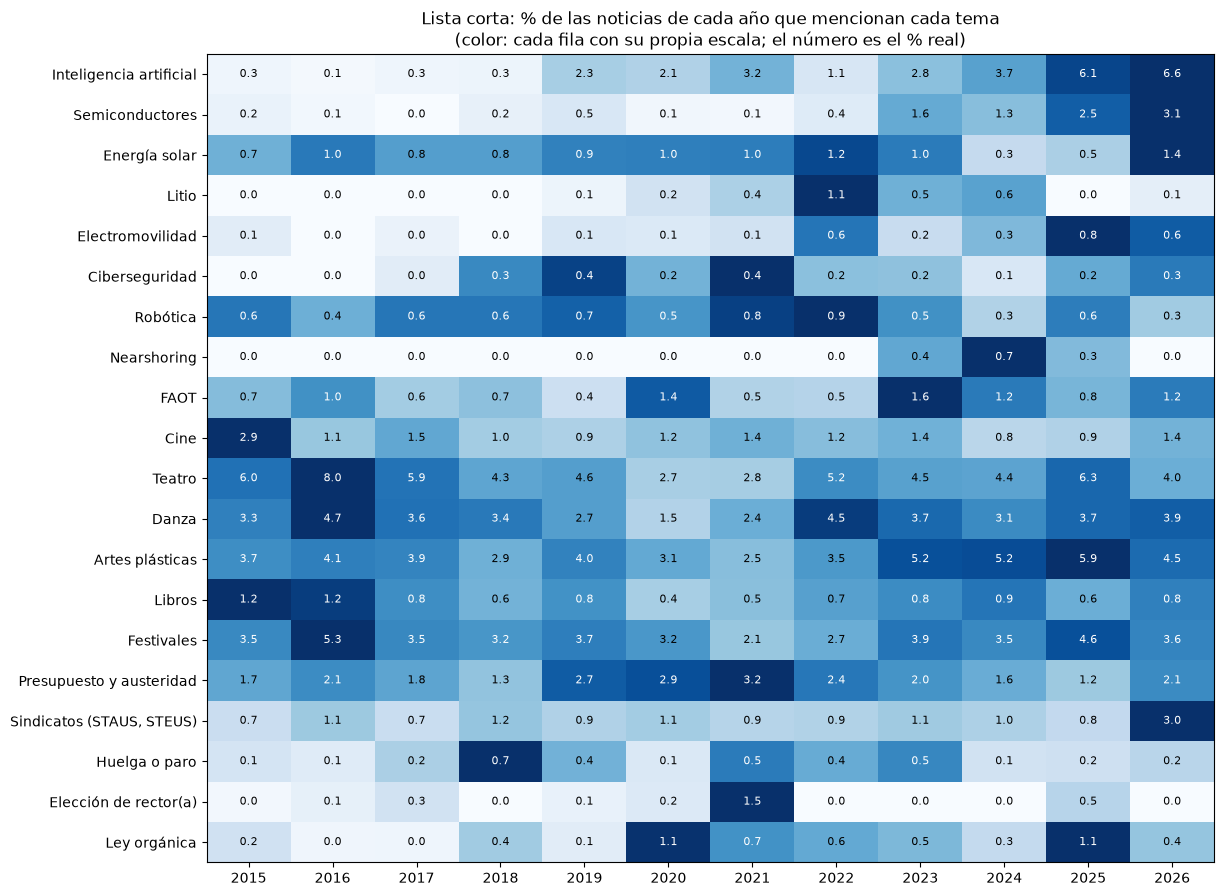

In [15]:
def porcentaje_por_anio(patron):
    """Porcentaje de las noticias de cada año cuyo texto contiene el patrón (sin distinguir mayúsculas)."""
    contiene = noticias["texto"].str.contains(patron, case=False)
    return contiene.groupby(noticias["anio"]).mean() * 100


LISTA_CORTA = {
    "Tecnología": {
        "Inteligencia artificial": "inteligencia artificial",
        "Semiconductores": "semiconductor",
        "Energía solar": "energía solar|fotovoltaic|paneles solares",
        "Litio": r"\blitio\b",
        "Electromovilidad": "electromovilidad|vehículos eléctricos|autos eléctricos",
        "Ciberseguridad": "ciberseguridad",
        "Robótica": "robótic",
        "Nearshoring": "nearshoring",
    },
    "Cultura": {
        "FAOT": "alfonso ortiz tirado|faot",
        "Cine": r"\bcine\b|cortometraje|largometraje",
        "Teatro": r"\bteatro\b",
        "Danza": r"\bdanza\b",
        "Artes plásticas": "artes plásticas|pintura|galería",
        "Libros": "feria del libro|presentación del libro|presentan libro",
        "Festivales": r"\bfestival\b",
    },
    "Vida universitaria": {
        "Presupuesto y austeridad": "presupuest|austeridad",
        "Sindicatos (STAUS, STEUS)": r"\bstaus\b|\bsteus\b",
        "Huelga o paro": r"\bhuelga|paro de labores",
        "Elección de rector(a)": "elección de rector|aspirantes a la rectoría|designación de rector|auscultación",
        "Ley orgánica": "ley orgánica",
    },
}

lista_corta = pd.DataFrame({
    etiqueta: porcentaje_por_anio(patron)
    for temas_del_grupo in LISTA_CORTA.values()
    for etiqueta, patron in temas_del_grupo.items()
}).T

dibujar_mapa(lista_corta, "Lista corta: % de las noticias de cada año que mencionan cada tema")

## 6. Vida universitaria: ¿cómo cuenta la universidad sus propios conflictos?

En la lista corta, huelgas y sindicatos casi no aparecen (menos del 1% de las notas casi todos los años).
Cuando aparecen, ¿cómo los presenta el portal? Los títulos de esas noticias:

In [16]:
conflictos = noticias[noticias["texto"].str.contains(r"\bhuelga|paro de labores|cierre de instalaciones|emplazamiento", case=False)
                      & noticias["texto"].str.contains(r"\bstaus\b|\bsteus\b|sindicato", case=False)]

print("Noticias sobre huelgas o paros de los sindicatos de la Unison:", len(conflictos))
conflictos[["fecha", "titulo"]].assign(fecha=conflictos["fecha"].dt.date)

Noticias sobre huelgas o paros de los sindicatos de la Unison: 30


,fecha,titulo
687,2015-04-16,Concretan Unison y Sindicatos negociaciones salariales
2881,2016-03-18,"Expropiación petrolera, para salvar el decoro de México: Lázaro Cárdenas del Río"
3045,2016-04-15,Acuerdos con sindicatos universitarios evitan paralización de labores
5158,2017-03-22,La reforma laboral será gradualmente justa al instrumentarse su implementación: Rodríguez Espinoza
5351,2017-04-28,Logra Unison acuerdos con sindicatos universitarios
5935,2017-09-05,Cuenta Unison con sus finanzas sanas: Enrique Fernando Velázquez Contreras
6123,2017-10-02,Atenderá Unison anticipadamente demandas sindicales
7066,2018-02-23,La huelga universitaria del 78 requiere de mayor estudio: Samuel Galaviz Moreno
7377,2018-04-10,Confía Rector en llegar a acuerdos con sindicatos
7417,2018-04-16,Llama rectoría al Steus a retomar la legalidad


## 7. Observaciones

### Los tres grupos (sección 3)

- **Tecnología** ocupa ~8% de las noticias hasta 2018, sube a 12–15% en 2020–2021 y vuelve a ~8–10%. Ojo: ese pico **no es progreso
  tecnológico**, es la pandemia: el tema "Tecnología digital e IA" incluye las clases y los eventos virtuales.
- **Cultura** baja de ~16% (2015–2016) a ~9% en 2020–2021 (eventos cancelados por la pandemia) y se recupera a 11–14%.
- **Vida universitaria** ronda 10–16% hasta 2021 y baja a ~8–9% en 2022–2025 (11% en 2026), en parte porque desaparecen los cargos
  de la estructura anterior (vicerrectores, Divisiones; ver notebook 02).

### Tecnología: temas con momentos claros (secciones 4 y 5)

- **El tema destacado de cada año** cuenta una historia ordenada: *clases virtuales* (2020), *litio* (2022–2023),
  *astronomía* (2024–2025, con los eclipses de 2023–2024) e *inteligencia artificial* (2026).
- **Inteligencia artificial** pasa de 0.3% de las notas (2015–2018) a ~2–3% (2019–2023) y a **6.6% en 2026**.
- **Semiconductores** casi no aparecen antes de 2023 (y cuando aparecen es como investigación en ciencia de materiales) y suben a **3.1% en 2026**,
  ya como industria y formación (*Semana de la Electrónica y Semiconductores*, programas de ingeniería).
  Es el ejemplo más claro de un tema de Sonora que la universidad hace suyo.
- **Litio** tiene su pico en **2022** (1.1%), **nearshoring** en **2024** (0.7%) y **electromovilidad** en 2022 y 2025.
  El *Plan Sonora* aparece en las notas desde 2022.
- Otros temas son **estables** y no marcan momentos: energía solar (~1% todos los años), robótica, divulgación científica.

### Cultura: un calendario, más que una tendencia

- La cultura es **constante y de temporada**: teatro (4–8%), artes plásticas (3–6%), danza (3–5%) y festivales (3–5%) aparecen
  todos los años, con una caída en 2020–2021 y recuperación después. Los "destacados" de cada año apenas superan su promedio
  (1.2–1.8 veces), salvo *Cine y televisión universitaria* en 2015, que es la cartelera del Canal 8.
- Lo que más crece son las **artes plásticas y exposiciones** (máximo en 2023–2025) y el **teatro** vuelve a su nivel en 2025.
- El **FAOT** tiene años altos (2020, 2023) y es el evento más fácil de comparar con Google Trends: ocurre cada enero.

### Vida universitaria: lo que el portal cuenta de sí mismo (sección 6)

- **Presupuesto y austeridad** se mencionan más en 2019–2022 (~3% de las notas).
- La **elección de rector(a)** aparece en 2021 y 2025 y la **ley orgánica** en 2020 y 2025.
- Los **conflictos con los sindicatos** casi no aparecen (huelgas: 0.1–0.7% de las notas), pero sí se ven sus fechas:
  2018 (el STEUS toma instalaciones), 2019, 2021, 2023 y **2026** (cierre de instalaciones por el STAUS; los sindicatos
  suben a 3% de las notas). Siempre con la voz de la administración: *"Llama rectoría al Steus a retomar la legalidad"*,
  *"Lamenta administración universitaria paralización de labores: realizó su máximo esfuerzo"*,
  *"Posicionamiento de la Unison ante cierre de instalaciones por el STAUS"*.
  Compararlas con la prensa dirá cuánto de cada conflicto cuenta el portal.

### Limitaciones

- Cada noticia cuenta solo en su **tema dominante**; una nota que mezcla temas se pierde en los demás.
- Las **etiquetas** de los temas las pusimos leyendo sus palabras; algunos temas mezclan cosas
  (*Libros e investigación social*, *Tecnología digital e IA* con las clases virtuales).
- Los temas específicos tienen **pocas noticias por año** (decenas): un evento grande puede mover el porcentaje.
- La búsqueda de conflictos también encuentra notas de historia (*la huelga universitaria del 78*, *2 de octubre*).
- 2026 está incompleto (hasta octubre).

### Siguiente paso

Comparar la **lista corta** con Google Trends (México y Sonora). Los mejores candidatos son los que tienen momentos claros:
**inteligencia artificial, semiconductores, litio, nearshoring, electromovilidad y el FAOT**.
Para la vida universitaria, los conflictos de **2018, 2023 y 2026** son buenos casos para comparar con la prensa.